# 06 — Cross-Validation Comparison: DNN With vs Without G1/G2

**Research question:** Does including first- and second-period grades improve prediction of the final performance category?

This notebook compares **the same DNN architecture and training settings** on two feature sets:

- **Early prediction:** 30 inputs, excluding `G1`, `G2`, `G3`.
- **Mid-course prediction:** 32 inputs, including `G1` and `G2`, excluding `G3`.

The target is derived from `G3`: Low (0–9), Average (10–13), Good (14–20).

**Evaluation rules:** Use only the 519-row development pool, with five **paired stratified outer folds**. Each outer training fold is split again to create an inner validation subset for Early Stopping. Scaling, one-hot encoding, label encoding and class weights are fitted only on the appropriate training subset. The outer fold is used **only for scoring**, not Early Stopping. The previously examined 130-row test subset is not used here.

This is an exploratory comparison, not an independent final test. Running multiple experiments against these folds can itself lead to selection bias.

## 1. Imports and reproducibility

Requires `tensorflow`, `scikit-learn`, `pandas`, `numpy`, and `matplotlib`. Five folds × two models means **10 DNN training runs**; execution can take several minutes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, recall_score
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
N_SPLITS = 5
MAX_EPOCHS = 100
PATIENCE = 10
BATCH_SIZE = 32
DROPOUT = 0.2
LEARNING_RATE = 0.001

tf.keras.utils.set_random_seed(SEED)
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


## 2. Load the dataset and isolate the development pool

We reproduce the original 80/20 stratified split with `random_state=42`. The test partition is set aside and **never passed to cross-validation**.

In [2]:
DATA_PATH = Path('../data/student-por.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError(f'CSV not found: {DATA_PATH.resolve()} — run this notebook from the notebooks folder.')

df = pd.read_csv(DATA_PATH, sep=';')

def categorize_performance(g3):
    if g3 <= 9:
        return 'Low'
    if g3 <= 13:
        return 'Average'
    return 'Good'

df['performance_category'] = df['G3'].apply(categorize_performance)
X_all = df.drop(columns=['G3', 'performance_category'])
y_all = df['performance_category']

X_dev, X_test_unused, y_dev, y_test_unused = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42, stratify=y_all
)
assert len(X_dev) == 519 and len(X_test_unused) == 130
assert X_dev.shape[1] == 32

print('Development data:', X_dev.shape)
print('Previously examined test partition (not used):', X_test_unused.shape)
print('Development class distribution:')
print(y_dev.value_counts())

Development data: (519, 32)
Previously examined test partition (not used): (130, 32)
Development class distribution:
performance_category
Average    284
Good       155
Low         80
Name: count, dtype: int64


## 3. Model architecture and per-fold preprocessing

The DNN uses `Dense(64) → Dropout(0.2) → Dense(32) → Dropout(0.2) → Dense(3)`, Adam (`0.001`), class weights, batch size 32, and Early Stopping on **inner validation loss** (patience 10, restore best weights).

For each outer fold, both feature configurations use the **same student indices** and the same inner validation split. This makes their comparison paired. A fresh model, encoder and preprocessor are created each time.

In [3]:
def build_model(input_dim, n_classes):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(64, activation='relu'),
        Dropout(DROPOUT),
        Dense(32, activation='relu'),
        Dropout(DROPOUT),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


def evaluate_one_fold(X_outer_train, X_outer_valid, y_outer_train, y_outer_valid,
                      include_grades, fold_number):
    # Inner validation is only for Early Stopping, never for final fold scoring.
    X_fit, X_inner_val, y_fit, y_inner_val = train_test_split(
        X_outer_train, y_outer_train, test_size=0.2,
        random_state=SEED, stratify=y_outer_train
    )

    if not include_grades:
        X_fit = X_fit.drop(columns=['G1', 'G2'])
        X_inner_val = X_inner_val.drop(columns=['G1', 'G2'])
        X_outer_valid = X_outer_valid.drop(columns=['G1', 'G2'])

    numeric_cols = X_fit.select_dtypes(include=['number']).columns.tolist()
    categorical_cols = X_fit.select_dtypes(include=['object', 'category']).columns.tolist()
    preprocessor = ColumnTransformer([
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ])
    X_fit_p = preprocessor.fit_transform(X_fit)
    X_inner_p = preprocessor.transform(X_inner_val)
    X_outer_p = preprocessor.transform(X_outer_valid)

    encoder = LabelEncoder()
    y_fit_e = encoder.fit_transform(y_fit)
    y_inner_e = encoder.transform(y_inner_val)
    y_outer_e = encoder.transform(y_outer_valid)

    classes = np.unique(y_fit_e)
    weights = compute_class_weight('balanced', classes=classes, y=y_fit_e)
    class_weights = dict(zip(classes.tolist(), weights.tolist()))

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED + fold_number)
    model = build_model(X_fit_p.shape[1], len(encoder.classes_))
    early_stopping = EarlyStopping(
        monitor='val_loss', patience=PATIENCE, restore_best_weights=True
    )
    history = model.fit(
        X_fit_p, y_fit_e,
        validation_data=(X_inner_p, y_inner_e),
        epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
        class_weight=class_weights, callbacks=[early_stopping], verbose=0
    )
    predictions = np.argmax(model.predict(X_outer_p, verbose=0), axis=1)
    low_index = int(encoder.transform(['Low'])[0])
    return {
        'fold': fold_number,
        'features': 'With G1/G2' if include_grades else 'Without G1/G2',
        'accuracy': accuracy_score(y_outer_e, predictions),
        'macro_f1': f1_score(y_outer_e, predictions, average='macro', zero_division=0),
        'low_recall': recall_score(y_outer_e, predictions, labels=[low_index],
                                   average='macro', zero_division=0),
        'epochs_trained': len(history.history['loss']),
        'outer_validation_size': len(y_outer_e)
    }

## 4. Run paired five-fold stratified cross-validation

Each of the five outer folds is scored exactly once for each configuration. The two configurations are compared on identical outer-fold students. **No results are prefilled**; run the cell to obtain your actual scores.

In [4]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
results = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_dev, y_dev), start=1):
    X_outer_train = X_dev.iloc[train_idx]
    X_outer_valid = X_dev.iloc[valid_idx]
    y_outer_train = y_dev.iloc[train_idx]
    y_outer_valid = y_dev.iloc[valid_idx]

    for include_grades in [False, True]:
        result = evaluate_one_fold(
            X_outer_train, X_outer_valid, y_outer_train, y_outer_valid,
            include_grades=include_grades, fold_number=fold
        )
        results.append(result)
        print(f"Fold {fold} | {result['features']:<14} | "
              f"Accuracy {result['accuracy']:.2%} | "
              f"Macro F1 {result['macro_f1']:.2%} | "
              f"Low recall {result['low_recall']:.2%} | "
              f"Epochs {result['epochs_trained']}")

results_df = pd.DataFrame(results)
display(results_df.style.format({
    'accuracy': '{:.2%}', 'macro_f1': '{:.2%}', 'low_recall': '{:.2%}'
}))


Fold 1 | Without G1/G2  | Accuracy 57.69% | Macro F1 58.44% | Low recall 75.00% | Epochs 38
Fold 1 | With G1/G2     | Accuracy 76.92% | Macro F1 76.65% | Low recall 87.50% | Epochs 36
Fold 2 | Without G1/G2  | Accuracy 48.08% | Macro F1 44.39% | Low recall 31.25% | Epochs 30
Fold 2 | With G1/G2     | Accuracy 83.65% | Macro F1 82.07% | Low recall 75.00% | Epochs 49
Fold 3 | Without G1/G2  | Accuracy 60.58% | Macro F1 58.23% | Low recall 56.25% | Epochs 35
Fold 3 | With G1/G2     | Accuracy 80.77% | Macro F1 80.31% | Low recall 75.00% | Epochs 38
Fold 4 | Without G1/G2  | Accuracy 50.00% | Macro F1 47.91% | Low recall 43.75% | Epochs 30
Fold 4 | With G1/G2     | Accuracy 76.92% | Macro F1 76.00% | Low recall 87.50% | Epochs 27
Fold 5 | Without G1/G2  | Accuracy 53.40% | Macro F1 52.84% | Low recall 56.25% | Epochs 39
Fold 5 | With G1/G2     | Accuracy 81.55% | Macro F1 81.25% | Low recall 75.00% | Epochs 38


,fold,features,accuracy,macro_f1,low_recall,epochs_trained,outer_validation_size
0,1,Without G1/G2,57.69%,58.44%,75.00%,38,104
1,1,With G1/G2,76.92%,76.65%,87.50%,36,104
2,2,Without G1/G2,48.08%,44.39%,31.25%,30,104
3,2,With G1/G2,83.65%,82.07%,75.00%,49,104
4,3,Without G1/G2,60.58%,58.23%,56.25%,35,104
5,3,With G1/G2,80.77%,80.31%,75.00%,38,104
6,4,Without G1/G2,50.00%,47.91%,43.75%,30,104
7,4,With G1/G2,76.92%,76.00%,87.50%,27,104
8,5,Without G1/G2,53.40%,52.84%,56.25%,39,103
9,5,With G1/G2,81.55%,81.25%,75.00%,38,103


## 5. Summarize the cross-validation scores

Mean and standard deviation describe variation **across folds**. They are not confidence intervals and should not be interpreted as guarantees of future performance.

In [5]:
summary = results_df.groupby('features')[['accuracy', 'macro_f1', 'low_recall']].agg(['mean', 'std'])
display(summary.style.format('{:.2%}'))

paired = results_df.pivot(index='fold', columns='features', values=['accuracy', 'macro_f1', 'low_recall'])
for metric in ['accuracy', 'macro_f1', 'low_recall']:
    delta = paired[(metric, 'With G1/G2')] - paired[(metric, 'Without G1/G2')]
    print(f'{metric}: mean paired improvement = {delta.mean()*100:+.2f} percentage points; '
          f'positive in {(delta > 0).sum()}/{N_SPLITS} folds')

accuracy: mean paired improvement = +26.02 percentage points; positive in 5/5 folds
macro_f1: mean paired improvement = +26.89 percentage points; positive in 5/5 folds
low_recall: mean paired improvement = +27.50 percentage points; positive in 5/5 folds


## 6. Visualize the paired results

Each line connects the two feature configurations evaluated on the **same outer fold**. Lines going upward indicate an improvement from adding G1/G2.

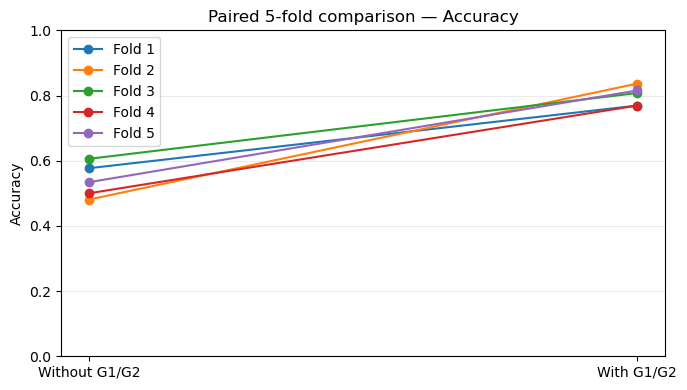

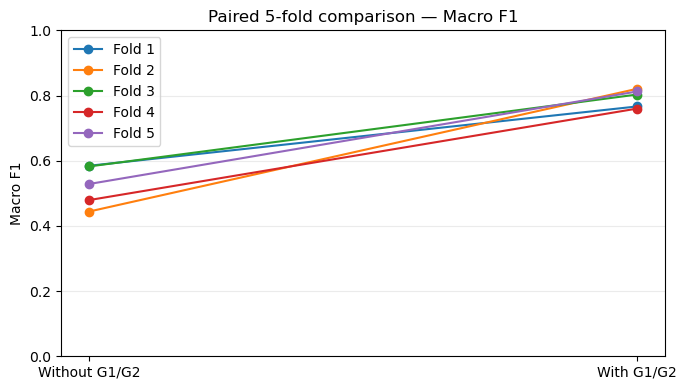

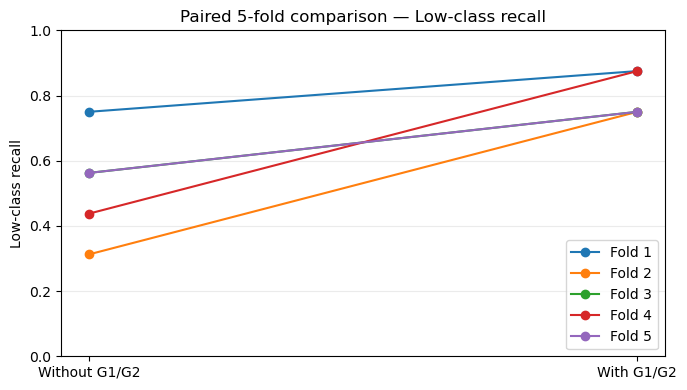

In [6]:
for metric, title in [
    ('accuracy', 'Accuracy'),
    ('macro_f1', 'Macro F1'),
    ('low_recall', 'Low-class recall')
]:
    wide = results_df.pivot(index='fold', columns='features', values=metric)
    plt.figure(figsize=(7, 4))
    for fold, row in wide.iterrows():
        plt.plot(['Without G1/G2', 'With G1/G2'],
                 [row['Without G1/G2'], row['With G1/G2']],
                 marker='o', label=f'Fold {fold}')
    plt.ylim(0, 1)
    plt.ylabel(title)
    plt.title(f'Paired 5-fold comparison — {title}')
    plt.grid(axis='y', alpha=0.25)
    plt.legend(loc='best')
    plt.tight_layout()
    plt.show()